# Fig. 2: mouse brain benchmarks

Panels of the final Fig. 2: b score maps (EnrichMap (null), the comparators and GSDensity, each from its minimum to its
maximum), c neighbourhood concordance, d contamination robustness, e noise robustness, f marker gene expression.

In [1]:
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

In [2]:
import scanpy as sc
import pandas as pd
import numpy as np
import gseapy as gp
import decoupler as dc
import enrichmap as em
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from scipy.sparse import issparse

In [3]:
sc.set_figure_params(frameon=False, fontsize=6)
sc.settings._vector_friendly = False
plt.rcParams["axes.grid"] = False

In [4]:
# set working directory
# repository root (the folder containing `notebooks/`); safe to re-run this cell
import sys
project_dir = os.getcwd()
if os.path.basename(project_dir) == "notebooks":
    project_dir = os.path.dirname(project_dir)
project_dir += "/"
sys.path.insert(0, project_dir + "notebooks")  # helpers.py and score_signatures.py
working_dir = project_dir
os.chdir(working_dir)

# set figure directory
figure_dir = working_dir + "figures/"
os.makedirs(figure_dir, exist_ok=True)

# processed data directory
processed_data = project_dir + "processed_data/"

# source data directory
source_dir = working_dir + "source_data/"
os.makedirs(source_dir, exist_ok=True)

In [5]:
colours = {
    "EnrichMap (null)": "#2f0bdf",
    "EnrichMap (smoothing)": "#a393f8",
    "AUCell": "#86bf6e",
    "GSVA": "#c76663",
    "ssGSEA": "#8f6eb0",
    "Z score": "#866342",
    "Scanpy": "#cf83bd",
    "GSDensity": "#e3a33b",
}
spot_size = 20

In [6]:
# Load data and signatures
adata = sc.read_h5ad(processed_data + "visium_brain_adata.h5ad")

cell_type_1 = "Pyramidal_layer"
cell_type_2 = "Striatum"

with open(project_dir + f"{cell_type_1}_signatures.pkl", "rb") as f:
    signature_dict_pyramidal = pickle.load(f)
with open(project_dir + f"{cell_type_2}_signatures.pkl", "rb") as f:
    signature_dict_striatum = pickle.load(f)

signatures_dict = {
    cell_type_1: signature_dict_pyramidal[f"{cell_type_1}_top10"],
    cell_type_2: signature_dict_striatum[f"{cell_type_2}_top10"],
}

In [7]:
# EnrichMap: null model (default) and smoothing-only
variants = {
    "EnrichMap (null)": dict(null_model=True),
    "EnrichMap (smoothing)": dict(null_model=False),
}

for ct, genes in signatures_dict.items():
    for name, kwargs in variants.items():
        em.tl.score(adata, gene_set=genes, score_key=f"{ct}_{name}", **kwargs)

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer_EnrichMap (null): 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer_EnrichMap (null): 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00,  9.23it/s]

Scoring Pyramidal_layer_EnrichMap (null): 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00,  9.09it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Pyramidal_layer_EnrichMap (smoothing): 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

Scoring Striatum_EnrichMap (null): 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 11.31it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring Striatum_EnrichMap (smoothing): 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring Striatum_EnrichMap (smoothing): 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 11.08it/s]

In [8]:
# Load data and signatures
cell_type_1 = "Pyramidal_layer"
cell_type_2 = "Striatum"

with open(project_dir + f"{cell_type_1}_signatures.pkl", "rb") as f:
    signature_dict_pyramidal = pickle.load(f)
with open(project_dir + f"{cell_type_2}_signatures.pkl", "rb") as f:
    signature_dict_cortex = pickle.load(f)

signatures_dict = {
    cell_type_1: signature_dict_pyramidal[f"{cell_type_1}_top10"],
    cell_type_2: signature_dict_cortex[f"{cell_type_2}_top10"],
}

X_dense = adata.X.toarray() if issparse(adata.X) else adata.X.copy()
gene_expr = pd.DataFrame(X_dense.T, index=adata.var_names, columns=adata.obs_names)
gene_expr_upper = gene_expr.copy()
gene_expr_upper.index = gene_expr_upper.index.str.upper()
signatures_dict_upper = {k: [g.upper() for g in v] for k, v in signatures_dict.items()}

In [9]:
# AUCell
signatures_dc = pd.DataFrame(
    [(key, gene) for key, genes in signatures_dict.items() for gene in genes],
    columns=["source", "target"],
)
dc.mt.aucell(adata, net=signatures_dc)
score_aucell = dc.pp.get_obsm(adata=adata, key="score_aucell")
score_aucell.obsm["score_aucell"].columns = [
    f"{cell_type_1}_aucell_score",
    f"{cell_type_2}_aucell_score",
]
adata.obs[[f"{cell_type_1}_aucell_score", f"{cell_type_2}_aucell_score"]] = (
    score_aucell.obsm["score_aucell"]
)

# GSVA
gsva = gp.gsva(data=gene_expr, gene_sets=signatures_dict, outdir=None, min_size=5)
es = gsva.res2d.pivot(index="Term", columns="Name", values="ES")
for ct in [cell_type_1, cell_type_2]:
    adata.obs[f"{ct}_gsva_score"] = (
        es.loc[ct].T.astype(float).reindex(adata.obs_names).values
    )

# ssGSEA
ssgsea = gp.ssgsea(
    data=gene_expr_upper,
    gene_sets=signatures_dict_upper,
    outdir=None,
    sample_norm_method="rank",
    no_plot=True,
    min_size=5,
)
nes = ssgsea.res2d.pivot(index="Term", columns="Name", values="NES")
for ct in [cell_type_1, cell_type_2]:
    adata.obs[f"{ct}_ssgsea_score"] = (
        nes.loc[ct].T.astype(float).reindex(adata.obs_names).values
    )

# z-score
for ct in [cell_type_1, cell_type_2]:
    common = [g for g in signatures_dict[ct] if g in gene_expr.index]
    adata.obs[f"{ct}_z_score"] = (
        gene_expr.loc[common].sum(axis=0) / np.sqrt(len(common))
    ).values

# scanpy
for ct in [cell_type_1, cell_type_2]:
    sc.tl.score_genes(
        adata, signatures_dict[ct], score_name=f"{ct}_scanpy_score", use_raw=False
    )

In [10]:
# GSDensity
for ct in signatures_dict:
    gsd = pd.read_csv(working_dir + f"data/gsd_cache/brain/{ct}.csv", index_col=0)
    adata.obs[f"{ct}_gsdensity_score"] = gsd["relevance"].reindex(adata.obs_names).values

# score column of each method
method_keys = {
    "EnrichMap (null)": "{ct}_EnrichMap (null)_score",
    "EnrichMap (smoothing)": "{ct}_EnrichMap (smoothing)_score",
    "AUCell": "{ct}_aucell_score",
    "GSVA": "{ct}_gsva_score",
    "ssGSEA": "{ct}_ssgsea_score",
    "Z score": "{ct}_z_score",
    "Scanpy": "{ct}_scanpy_score",
    "GSDensity": "{ct}_gsdensity_score",
}

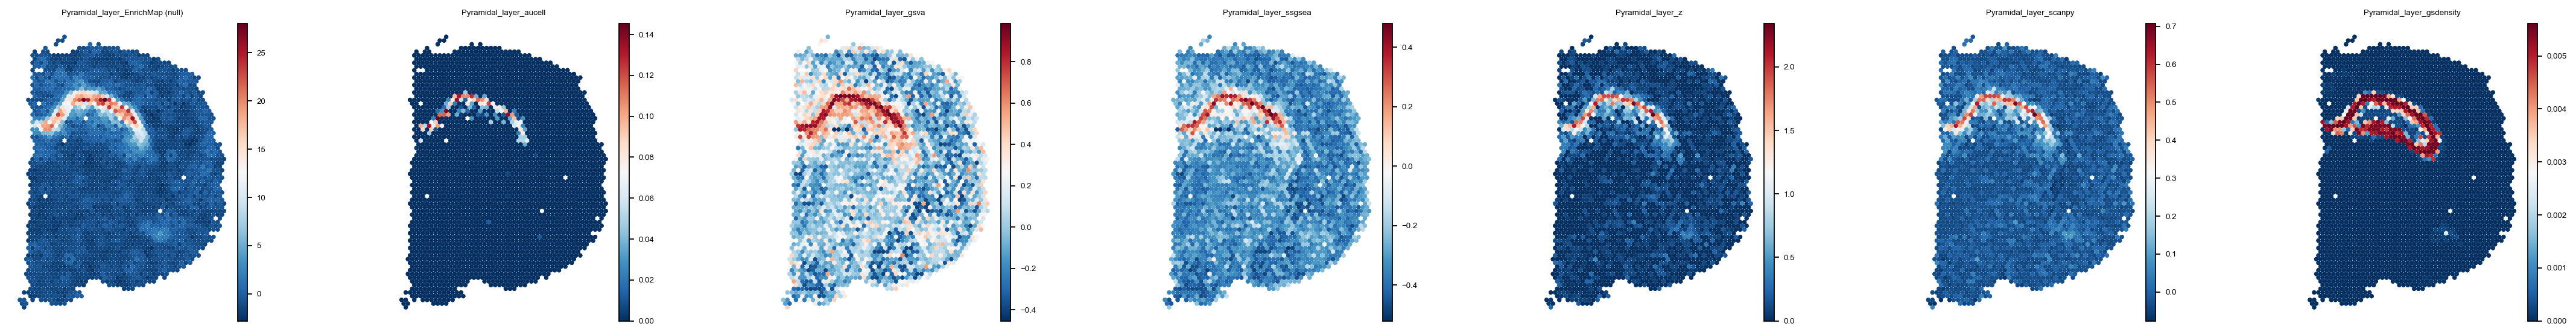

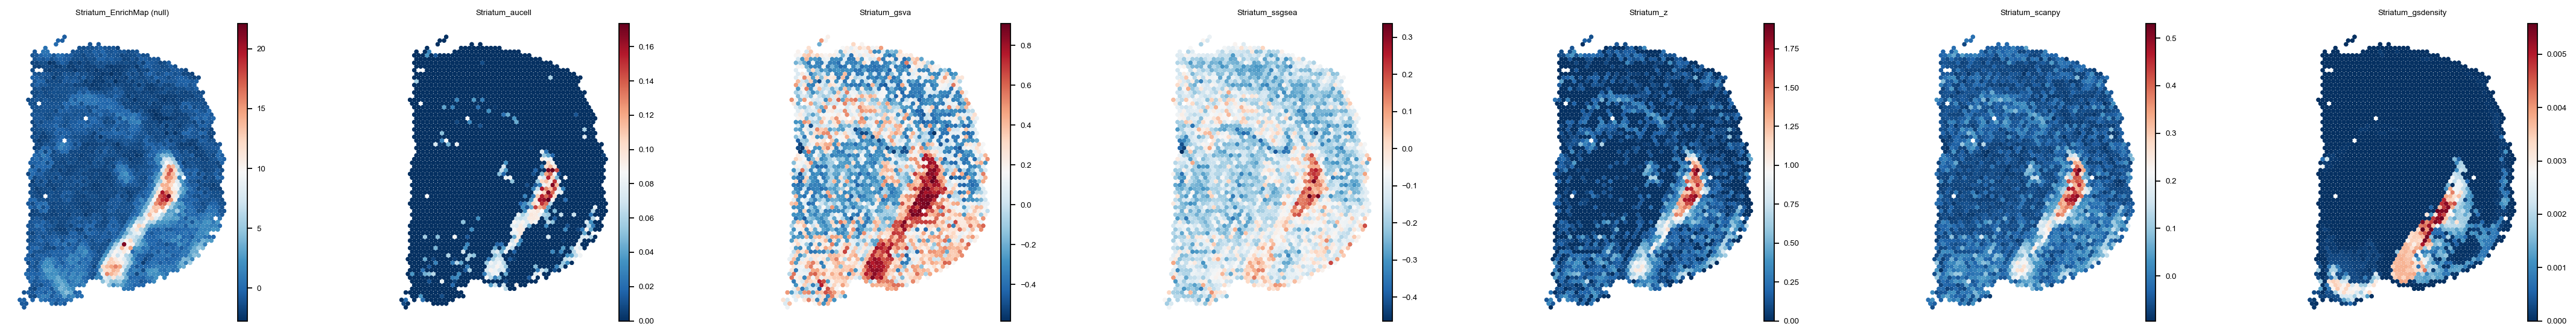

In [11]:
# 5. Fig. 2b: score maps of EnrichMap (null), the comparators and GSDensity, from minimum to maximum
coords = adata.obsm["spatial"]
for ct in signatures_dict:
    keys = [k.format(ct=ct) for m, k in method_keys.items() if m != "EnrichMap (smoothing)"]
    em.pl.spatial_enrichmap(
        adata,
        score_key=keys,
        shape=None,
        vcenter=None,
        size=spot_size,
        ncols=7,
        save=f"Fig2b_maps_{ct}.pdf",
    )
    maps = adata.obs[keys].copy()
    maps.insert(0, "y", coords[:, 1])
    maps.insert(0, "x", coords[:, 0])
    maps.to_csv(source_dir + f"Fig2b_maps_{ct}.csv")

In [12]:
from helpers import (
    benchmark_spatial_concordance,
    benchmark_contamination,
    benchmark_noise_robustness,
    make_enrichmap_null_scorer,
    make_enrichmap_scorer,
    make_aucell_scorer,
    make_gsva_scorer,
    make_ssgsea_scorer,
    make_zscore_scorer,
    make_scanpy_scorer,
    plot_benchmark_curve,
    set_box_ratio,
)

In [13]:
scoring_functions = {
    "EnrichMap (null)": make_enrichmap_null_scorer(),
    "EnrichMap (smoothing)": make_enrichmap_scorer(),
    "AUCell": make_aucell_scorer(),
    "GSVA": make_gsva_scorer(),
    "ssGSEA": make_ssgsea_scorer(),
    "Z score": make_zscore_scorer(),
    "Scanpy": make_scanpy_scorer(),
}

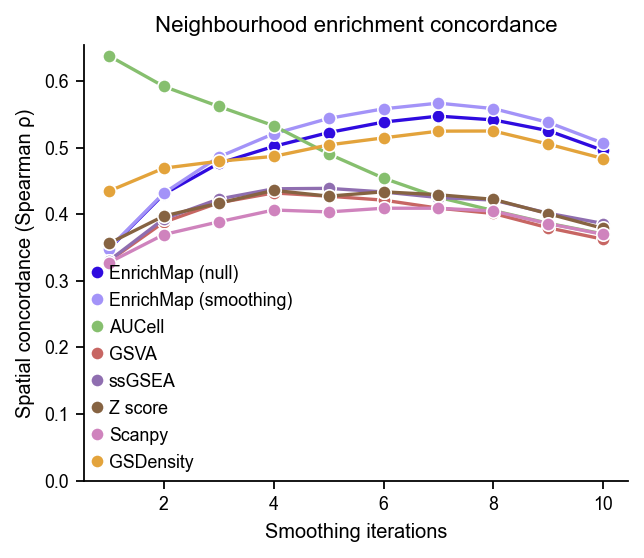

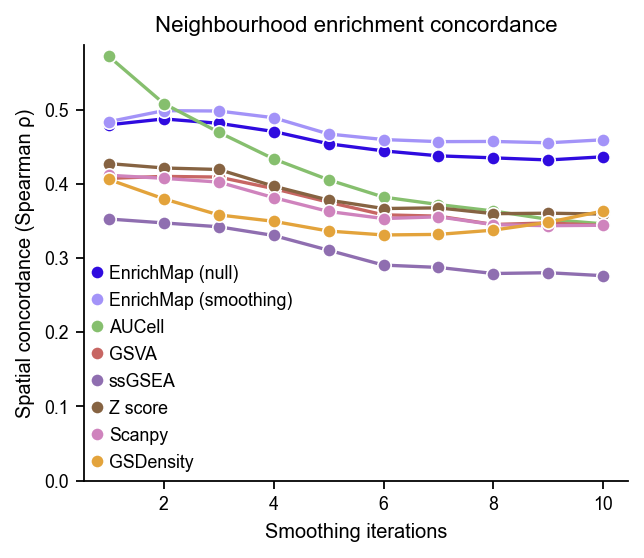

In [14]:
# 8. Fig. 2c: neighbourhood concordance
concordance = []
for ct in signatures_dict:
    keys = {k.format(ct=ct): method for method, k in method_keys.items()}
    res = benchmark_spatial_concordance(
        adata,
        score_keys=list(keys),
        label_source="cluster",
        positive_class=ct,
        n_neighbors=6,
        smoothing_iterations=list(range(1, 11)),
        plot=False,
    )
    res["method"] = res["method"].map(keys)
    plot_benchmark_curve(
        res,
        x="smoothing_iter",
        y="concordance",
        palette=colours,
        xlabel="Smoothing iterations",
        ylabel="Spatial concordance (Spearman ρ)",
        title="Neighbourhood enrichment concordance",
        ylim=(0, None),
        errorbar=None,
        figsize=(4, 4),
        save=figure_dir + f"Fig2c_concordance_{ct}.pdf",
    )
    res["region"] = ct
    concordance.append(res)
concordance = pd.concat(concordance)
concordance.to_csv(source_dir + "Fig2c_concordance.csv", index=False)

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 10.93it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 11.43it/s]

... (376 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 50/50 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 50/50 genes found: 100%|██████████| 1/1 [00:00<00:00,  3.56it/s]

Scoring _bench: 50/50 genes found: 100%|██████████| 1/1 [00:00<00:00,  3.54it/s]

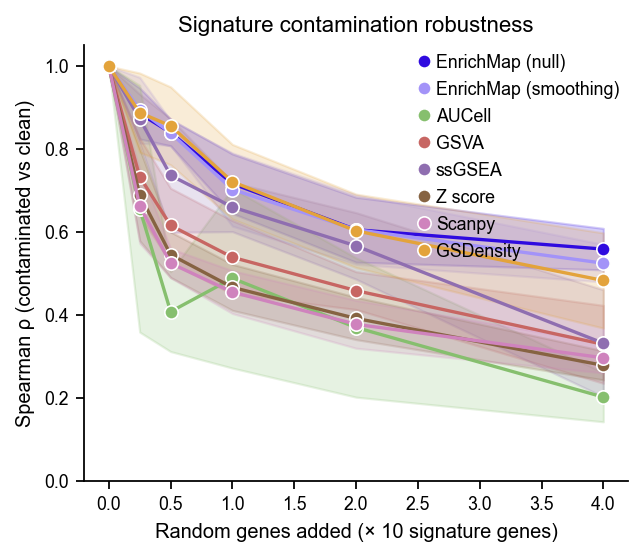

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 16.72it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 14.46it/s]

... (363 outputs left out)

Scoring _bench: 50/50 genes found: 100%|██████████| 1/1 [00:00<00:00, 15.46it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 50/50 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 50/50 genes found: 100%|██████████| 1/1 [00:00<00:00, 11.21it/s]

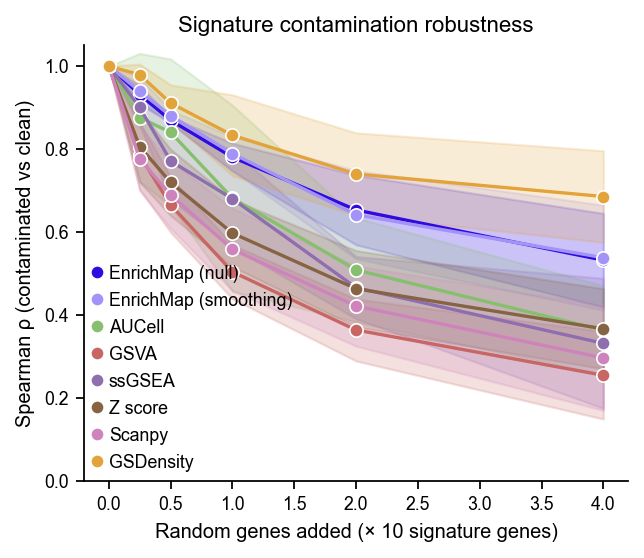

In [15]:
# 9. Fig. 2d: contamination robustness (GSDensity from the cache)
gsd_robustness = pd.read_csv(working_dir + "data/gsd_cache/brain/REV_Fig2/gsdensity_robustness.csv")
contamination = []
for ct in signatures_dict:
    res = benchmark_contamination(
        adata,
        gene_set=signatures_dict[ct],
        scoring_functions=scoring_functions,
        contamination_fractions=[0.0, 0.25, 0.5, 1.0, 2.0, 4.0],
        n_repeats=10,
        plot=False,
    )
    gsd = gsd_robustness.query("experiment == 'contamination' and region == @ct")
    res = pd.concat([res, pd.DataFrame({
        "method": "GSDensity", "contamination": gsd["x"], "repeat": gsd["repeat"], "correlation": gsd["correlation"],
    })])
    n_sig = sum(g in adata.var_names for g in signatures_dict[ct])
    plot_benchmark_curve(
        res,
        x="contamination",
        y="correlation",
        palette=colours,
        figsize=(4, 4),
        xlabel=f"Random genes added (× {n_sig} signature genes)",
        ylabel="Spearman ρ (contaminated vs clean)",
        title="Signature contamination robustness",
        save=figure_dir + f"Fig2d_contamination_{ct}.pdf",
    )
    res["region"] = ct
    contamination.append(res)
contamination = pd.concat(contamination)
contamination.to_csv(source_dir + "Fig2d_contamination.csv", index=False)

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 16.62it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 11.72it/s]

... (176 outputs left out)

Scoring _bench: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 17.10it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 17.21it/s]

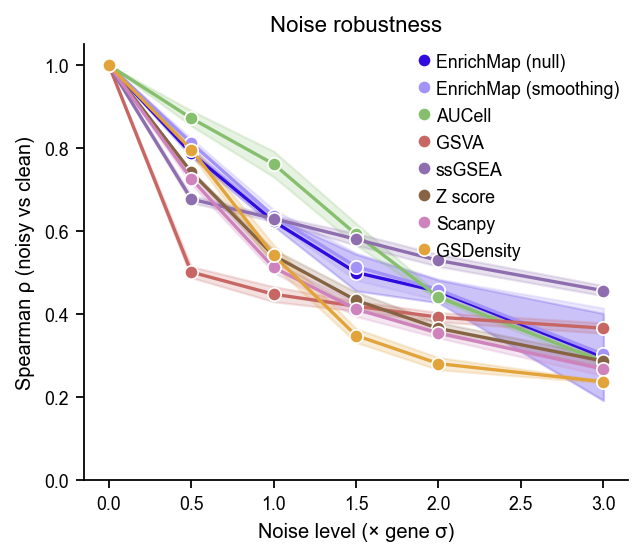

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 11.89it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 11.77it/s]

... (176 outputs left out)

Scoring _bench: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 17.96it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found:   0%|          | 0/1 [00:00<?, ?it/s]

Scoring _bench: 10/10 genes found: 100%|██████████| 1/1 [00:00<00:00, 17.45it/s]

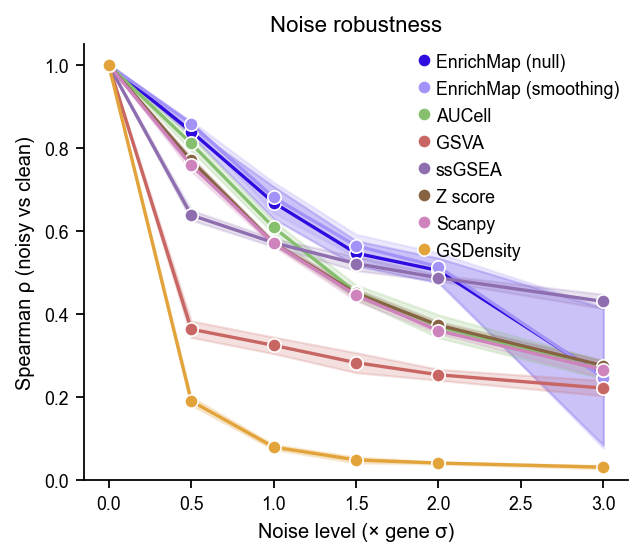

In [16]:
# 10. Fig. 2e: noise robustness
noise = []
for ct in signatures_dict:
    res = benchmark_noise_robustness(
        adata,
        gene_set=signatures_dict[ct],
        scoring_functions=scoring_functions,
        noise_levels=[0.0, 0.5, 1.0, 1.5, 2.0, 3.0],
        n_repeats=5,
        plot=False,
    )
    gsd = gsd_robustness.query("experiment == 'noise' and region == @ct")
    res = pd.concat([res, pd.DataFrame({
        "method": "GSDensity", "noise_level": gsd["x"], "repeat": gsd["repeat"], "correlation": gsd["correlation"],
    })])
    plot_benchmark_curve(
        res,
        x="noise_level",
        y="correlation",
        palette=colours,
        xlabel="Noise level (× gene σ)",
        ylabel="Spearman ρ (noisy vs clean)",
        title="Noise robustness",
        figsize=(4, 4),
        save=figure_dir + f"Fig2e_noise_{ct}.pdf",
    )
    res["region"] = ct
    noise.append(res)
noise = pd.concat(noise)
noise.to_csv(source_dir + "Fig2e_noise.csv", index=False)

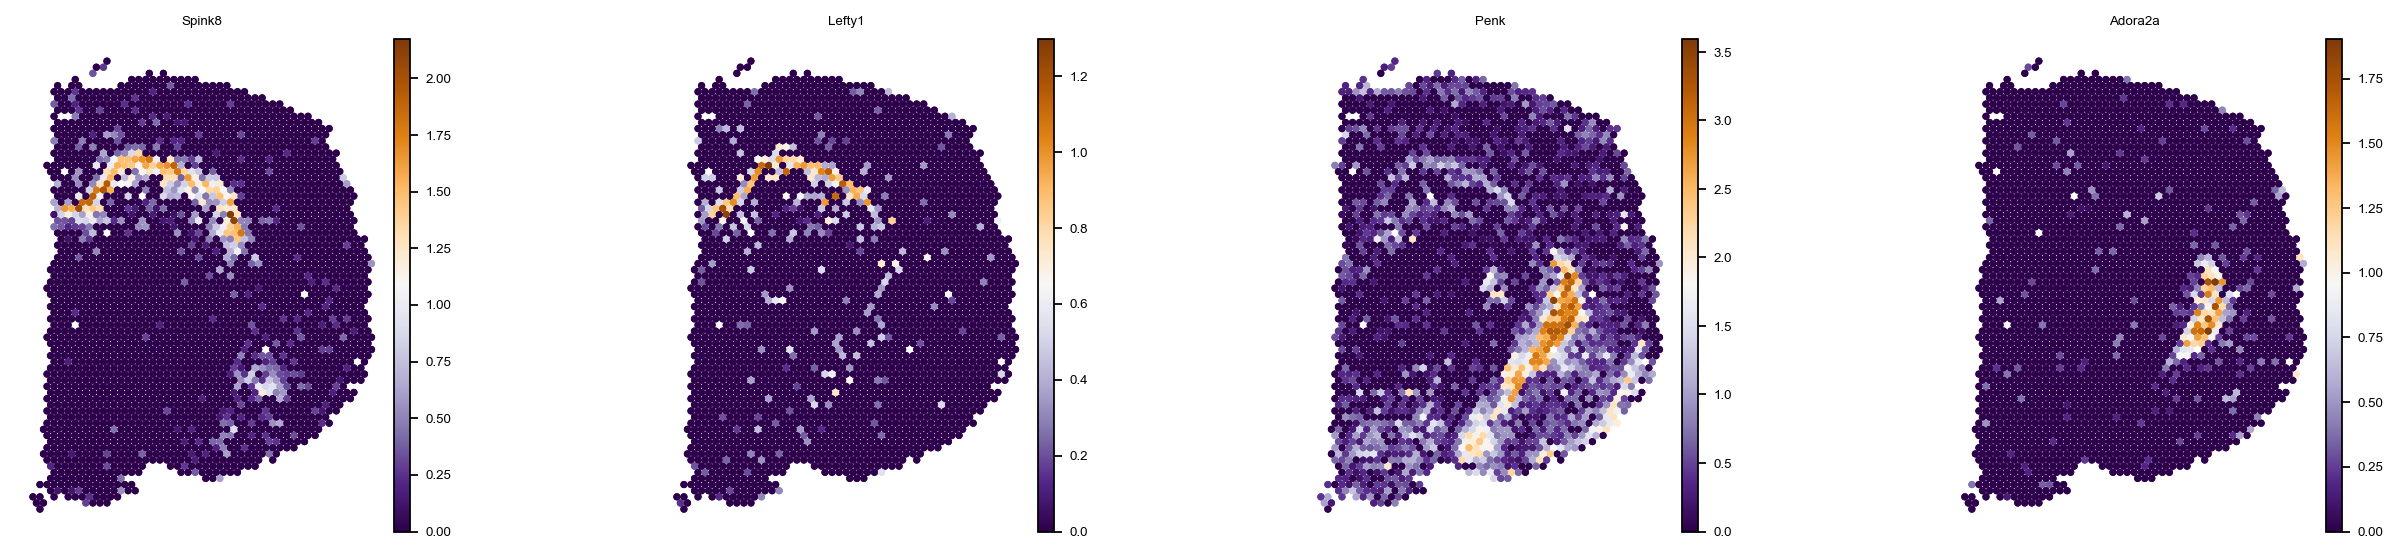

In [17]:
# 11. Fig. 2f: marker genes, log1p-normalised expression
top_genes = ["Spink8", "Lefty1", "Penk", "Adora2a"]
em.pl.spatial_enrichmap(
    adata,
    score_key=top_genes,
    layer="log1p_norm",
    vcenter=None,
    cmap="PuOr_r",
    ncols=4,
    save="Fig2f_top_genes.pdf",
    shape=None,
    size=spot_size,
)
expr = sc.get.obs_df(adata, keys=top_genes, layer="log1p_norm")
expr.insert(0, "y", coords[:, 1])
expr.insert(0, "x", coords[:, 0])
expr.to_csv(source_dir + "Fig2f_top_genes.csv")